# uxrd_phasemap_id13 quick start
Unsupervised phase mapping of a scanning micro-XRD map, demonstrated on synthetic data with known ground truth. For real data replace the first cell with `xmap = load_ewoks_h5('dq_scan.h5')`.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from uxrd_phasemap_id13 import make_synthetic_map, PhaseMapper, snip_baseline, phase_fraction
from uxrd_phasemap_id13.plotting import plot_label_map, plot_mean_patterns, plot_embedding

xmap, truth = make_synthetic_map(shape=(80, 80), n_particles=60, impurity_particles=3, seed=1)
xmap

XRDMap(intensity=array([[5., 9., 5., ..., 3., 2., 3.],
       [4., 4., 5., ..., 6., 4., 0.],
       [1., 8., 5., ..., 5., 3., 3.],
       ...,
       [7., 8., 6., ..., 2., 2., 5.],
       [6., 7., 8., ..., 5., 3., 4.],
       [5., 8., 6., ..., 3., 4., 8.]], shape=(6400, 800), dtype=float32), q=array([0.8       , 0.80525657, 0.81051314, 0.81576971, 0.82102628,
       0.82628285, 0.83153942, 0.83679599, 0.84205257, 0.84730914,
       0.85256571, 0.85782228, 0.86307885, 0.86833542, 0.87359199,
       0.87884856, 0.88410513, 0.8893617 , 0.89461827, 0.89987484,
       0.90513141, 0.91038798, 0.91564456, 0.92090113, 0.9261577 ,
       0.93141427, 0.93667084, 0.94192741, 0.94718398, 0.95244055,
       0.95769712, 0.96295369, 0.96821026, 0.97346683, 0.9787234 ,
       0.98397997, 0.98923655, 0.99449312, 0.99974969, 1.00500626,
       1.01026283, 1.0155194 , 1.02077597, 1.02603254, 1.03128911,
       1.03654568, 1.04180225, 1.04705882, 1.05231539, 1.05757196,
       1.06282854, 1.06808511, 1.07

## 1. Background removal (SNIP)
The smooth amorphous/air scattering is estimated per pattern and subtracted, leaving only Bragg peaks.

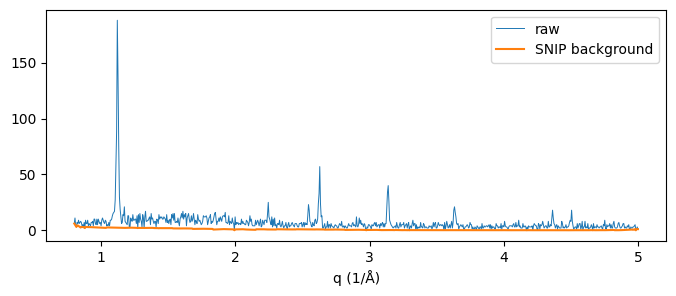

In [2]:
i = np.flatnonzero(truth == 1)[10]
y = xmap.intensity[i]
plt.figure(figsize=(8, 3))
plt.plot(xmap.q, y, lw=0.7, label='raw')
plt.plot(xmap.q, snip_baseline(y, 30), label='SNIP background')
plt.xlabel('q (1/Å)'); plt.legend();

## 2. Run the pipeline
The texture-sensitive 00l window (1.0–1.25 Å⁻¹) is excluded from the features; k is chosen by silhouette score.

In [3]:
res = PhaseMapper(exclude_q=[(1.0, 1.25)], n_clusters=[2, 3, 4, 5], snip_iterations=30, n_nmf=3).fit(xmap)
print(res.summary())
both = res.foreground & (truth >= 0)
print('ARI vs ground truth:', round(adjusted_rand_score(truth[both], res.labels[both]), 3))

map 80x80, 800 q-bins (0.80-5.00 1/A)
foreground: 2375 / 6400 points (threshold 1413 counts)
PCA explained variance (first 5): 0.306, 0.030, 0.010, 0.003, 0.003
model selection: k=2: 0.736, k=3: 0.758, k=4: 0.480, k=5: 0.333
  cluster 0: 1510 points
  cluster 1: 833 points
  cluster 2: 32 points
ARI vs ground truth: 1.0


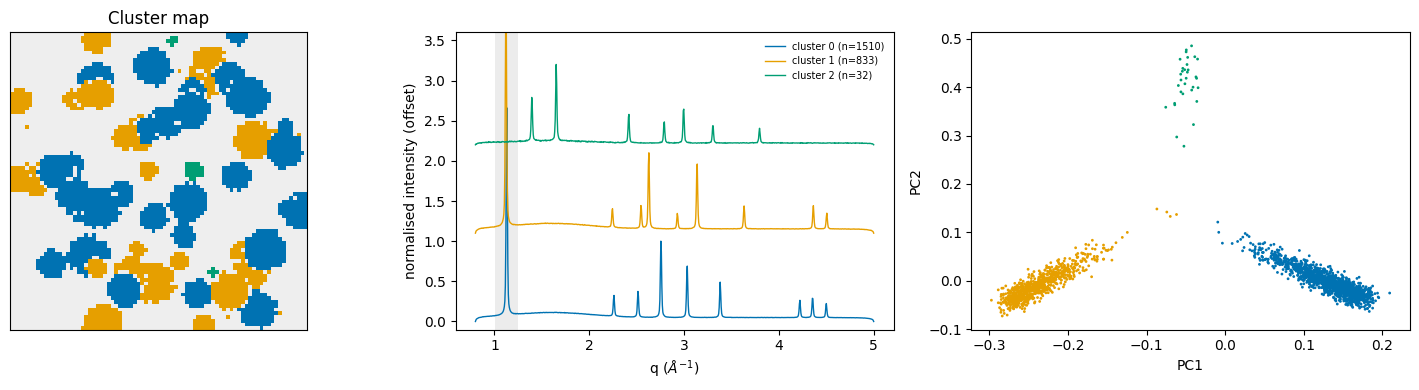

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plot_label_map(res, ax[0])
plot_mean_patterns(res, ax[1])
plot_embedding(res, ax[2])
plt.tight_layout()

## 3. NMF components
Non-negative factorisation gives additive, physically interpretable component patterns and abundance maps.

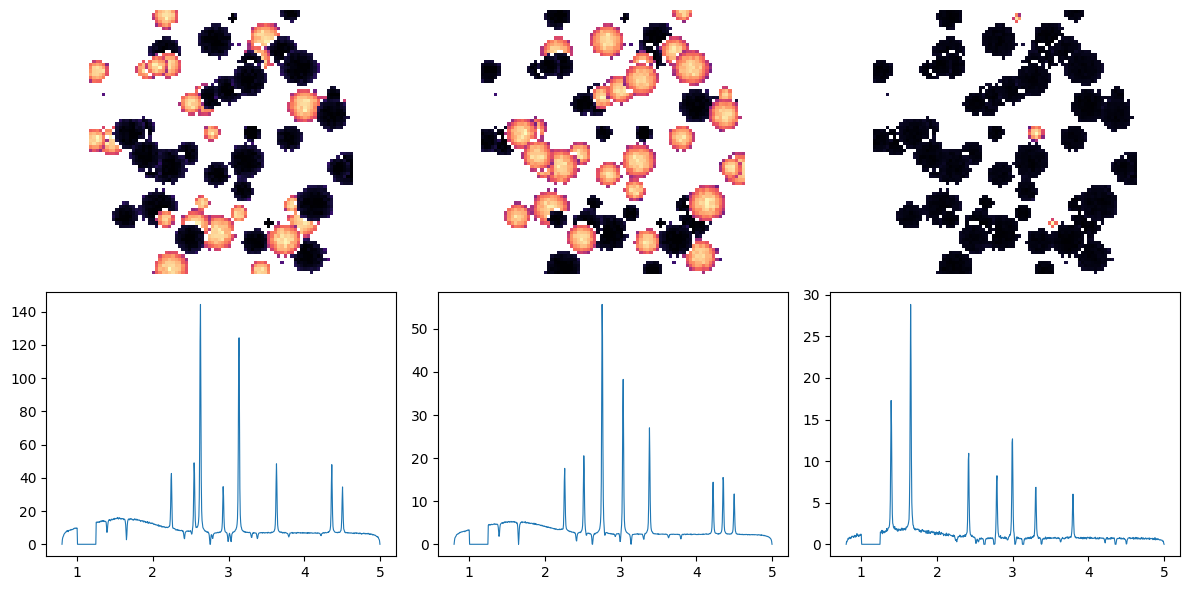

In [5]:
k = res.nmf_patterns.shape[0]
fig, ax = plt.subplots(2, k, figsize=(4 * k, 6))
for j in range(k):
    ax[0, j].imshow(xmap.to_image(res.nmf_maps[:, j]), origin='lower', cmap='magma')
    ax[0, j].set_axis_off()
    ax[1, j].plot(res.q, res.nmf_patterns[j], lw=0.8)
plt.tight_layout()

## 4. Cross-check with a classical ROI ratio
Marker reflections that belong to only one polytype give a per-pixel P2/(P2+P3) intensity ratio.

In [6]:
from uxrd_phasemap_id13.synthetic import hexagonal_q
m_p2 = hexagonal_q(2.885, 11.12, [(1, 0, 2), (1, 0, 3)])
m_p3 = hexagonal_q(2.880, 16.80, [(0, 1, 2), (0, 1, 5)])
frac = phase_fraction(res.peaks, res.q, {'P2': m_p2, 'P3': m_p3})['P2']
for c in range(res.n_clusters):
    print(f'cluster {c}: median P2 fraction = {np.nanmedian(frac[res.labels == c]):.2f}')

cluster 0: median P2 fraction = 0.96
cluster 1: median P2 fraction = 0.04
cluster 2: median P2 fraction = 0.00
